# 01 · Universe and data audit

**Purpose.** Before any signal is tested, establish *what can honestly be tested*: which
companies belonged to the opportunity set on each date, which of them have recoverable
price histories from free sources, and which vendor errors would otherwise contaminate
the results.

**Rules applied here and carried through the project**
1. *Point-in-time membership.* A company is in the universe only between the dates it was
   a listed pure-play in its segment. Merged, bankrupt and taken-private names stay in.
2. *Total returns are rebuilt, not downloaded.* Return = (price + cash distribution) /
   previous price, with split ratios applied explicitly. Vendor "adjusted close" series
   miss liquidating and special distributions.
3. *Official FX.* NOK-listed returns are converted with the Federal Reserve H.10 rate.
4. *No trade, no return.* Zero-volume days are stale quotes, not 0% returns.
5. *Takeover freeze.* From the first public bid, a stock trades on deal terms; no new
   signals are taken on it.

In [1]:
import pandas as pd, matplotlib.pyplot as plt
from shiplab import panel, charts, prices, screens, qa
from shiplab.universe import load_register, membership, deal_frozen
pd.set_option("display.max_rows", 80, "display.width", 140)
reg = load_register()
p = panel.build()
member = membership(p.total_return.index)
inv = screens.investable(p, frozen=deal_frozen(p.total_return.index))
print(f"Register: {len(reg)} companies | tradable with data: {len(p.raw)} | "
      f"download failures: {len(p.failures)}")

Register: 73 companies | tradable with data: 54 | download failures: 0


## 1. The opportunity set, including the companies that no longer exist

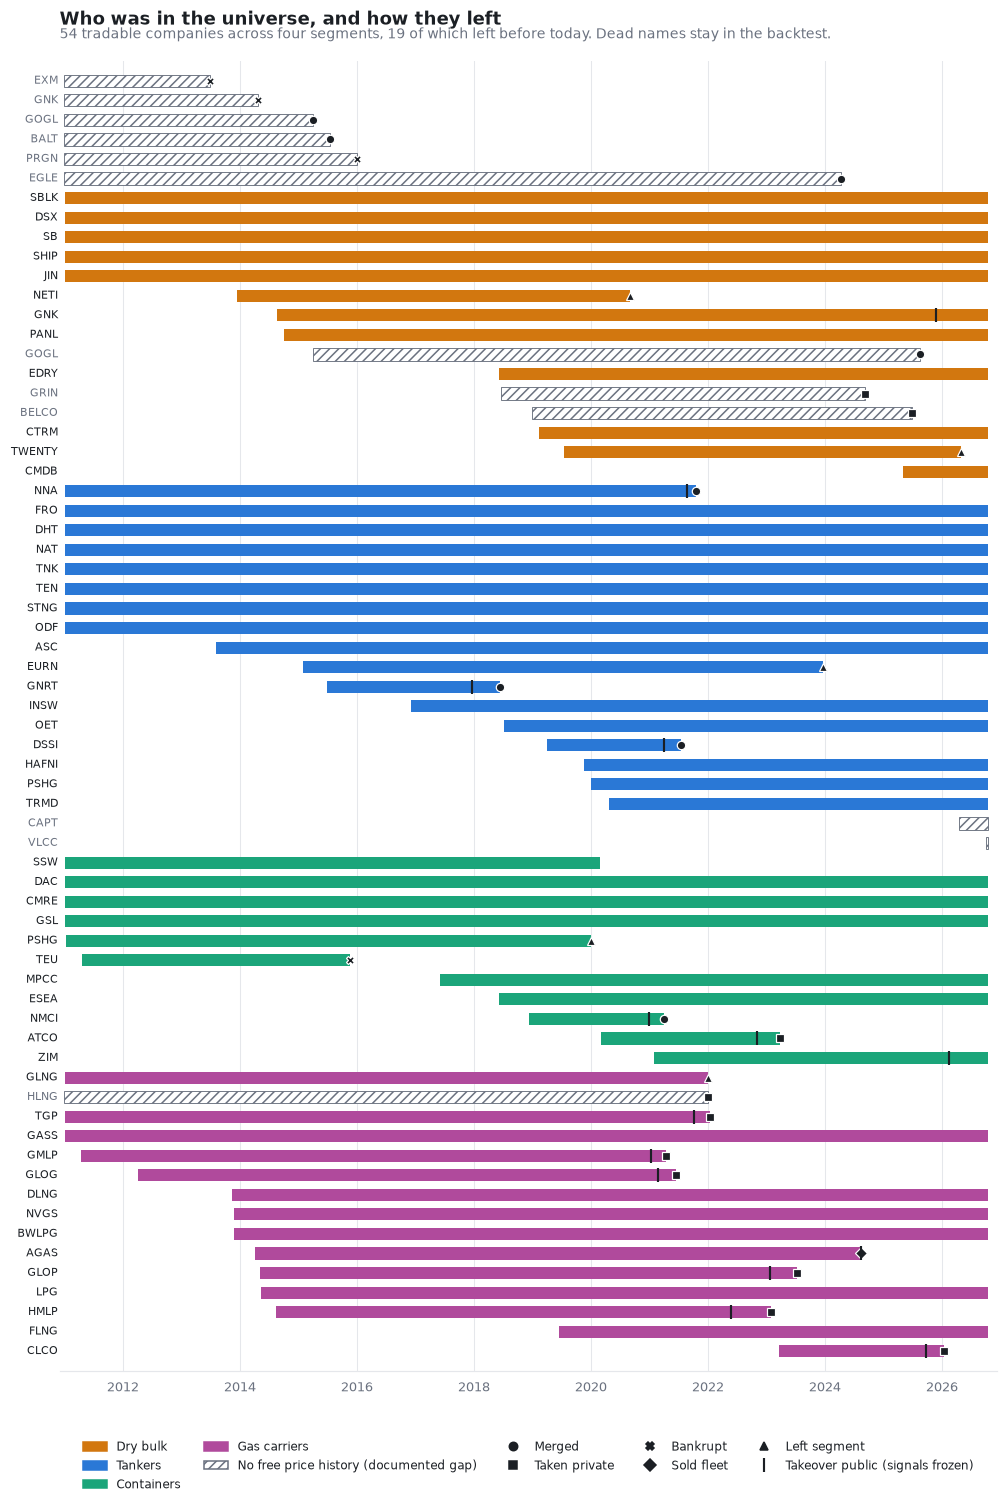

In [2]:
first = p.total_return.apply(lambda s: s.first_valid_index()).dropna()
fig = charts.universe_timeline(reg, p.total_return.index, first)
charts.save(fig, "01_universe_timeline"); plt.show()

In [3]:
summary = (reg.assign(status=lambda d: d["exit_type"].where(d["include"], "data gap / excluded"))
              .groupby(["segment", "status"]).size().unstack(fill_value=0))
summary

status,active,asset_sale,data gap / excluded,distress,merger_stock,reclassified,renamed,take_private
segment,,,,,,,,
containers,6,0,0,1,1,1,1,1
dry_bulk,10,0,9,0,0,2,0,0
excluded,0,0,7,0,0,0,0,0
gas,6,1,1,0,0,1,0,6
tankers,13,0,2,0,3,1,0,0


## 2. Survivorship: how much a survivor-only backtest would overstate

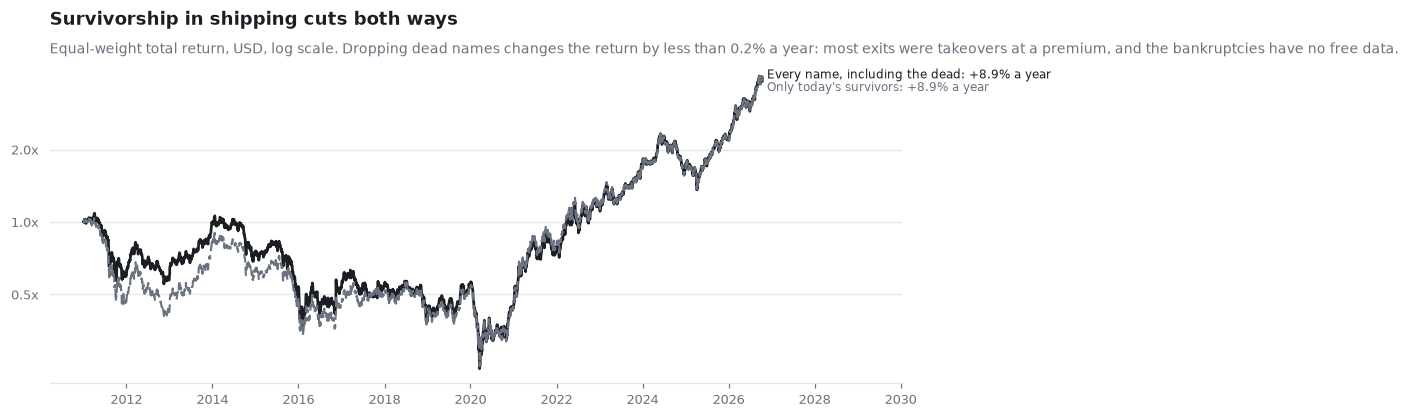

In [4]:
fig, gap = charts.survivorship(p.total_return, reg)
charts.save(fig, "01_survivorship"); plt.show()

## 3. Vendor errors found and fixed

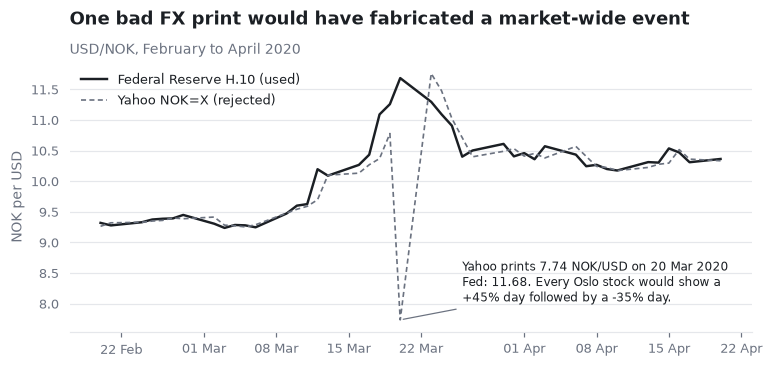

In [5]:
fig = charts.fx_glitch(prices.load("yahoo", "NOK=X")["close"], prices.fred("DEXNOUS"))
charts.save(fig, "01_fx_glitch"); plt.show()

In [6]:
print("Bad prints collapsed (spike fully reversed next day):")
display(p.repairs)
print("Remaining single-day moves beyond ±40% (each checked; real events or micro-caps "
      "removed by the liquidity screen):")
display(qa.extreme_moves(p.total_return, 0.4))

Bad prints collapsed (spike fully reversed next day):


,date,id,return,next_return,two_day
0,2012-08-01,DAC,-0.397022,0.699588,0.024814


Remaining single-day moves beyond ±40% (each checked; real events or micro-caps removed by the liquidity screen):


,date,id,return
0,2011-11-22,FRO,-0.410405
1,2013-01-04,SHIP,0.567308
2,2013-01-28,SHIP,0.413793
3,2015-05-15,PANL,0.406844
4,2015-12-17,TGP,-0.509793
5,2016-01-22,GLNG,0.506700
6,2016-01-27,SHIP,0.833333
7,2016-03-01,GSL,-0.400943
8,2016-03-07,GNK,0.525000
9,2016-03-07,PSHG_C,0.484645


## 4. Coverage

In [7]:
cov = qa.coverage(p.total_return, member)
cov.join(reg.set_index("id")[["segment", "source"]]).query("expected_days > 0").head(15)

,expected_days,days_with_data,coverage,segment,source
id,,,,,
AGAS,2612,1716,0.656968,gas,tiingo
SHIP,3969,3305,0.832703,dry_bulk,yahoo
OET,2081,1911,0.918309,tankers,yahoo
MPCC,2357,2218,0.941027,containers,yahoo
ODF,3969,3749,0.944570,tankers,yahoo
HMLP,2135,2046,0.958314,gas,tiingo
HAFNI,1741,1683,0.966686,tankers,yahoo
JIN,3969,3846,0.969010,dry_bulk,yahoo
TWENTY,1709,1657,0.969573,dry_bulk,yahoo


## 5. Liquidity and breadth: where segment-neutral trading is feasible

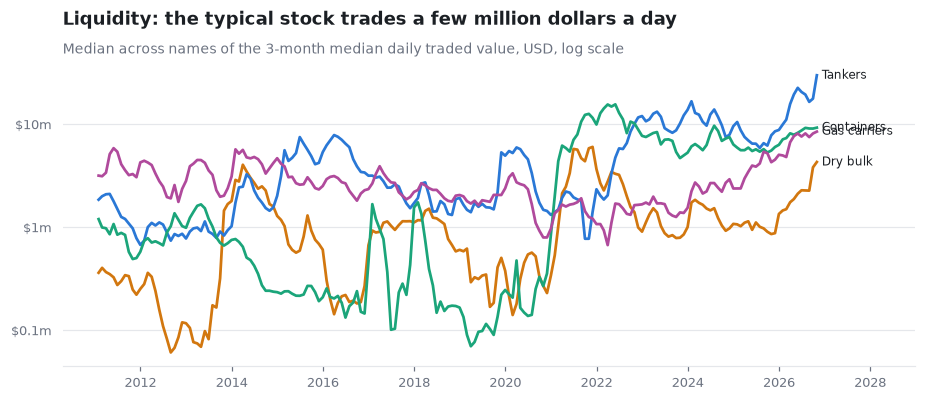

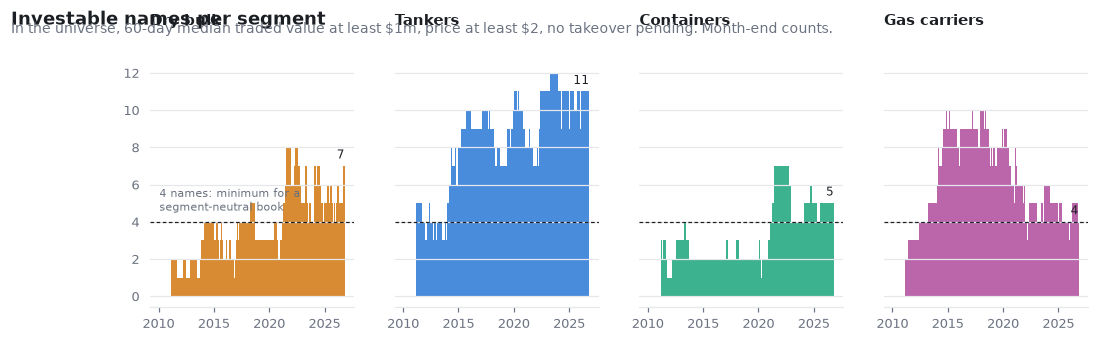

In [8]:
fig = charts.adv_by_segment(p.dollar_volume, member, reg)
charts.save(fig, "01_liquidity"); plt.show()
fig = charts.breadth(inv, reg)
charts.save(fig, "01_breadth"); plt.show()

In [9]:
seg = reg.set_index("id")["segment"]
counts = inv.resample("ME").last().T.groupby(seg).sum().T
feasible = (counts >= 4)
feasible.resample("YE").mean().round(2).rename(columns=str).loc["2011":]

segment,containers,dry_bulk,gas,tankers
Date,,,,
2011-12-31,0.00,0.00,0.00,0.83
2012-12-31,0.00,0.00,0.67,0.75
2013-12-31,0.25,0.00,1.00,0.58
2014-12-31,0.00,0.92,1.00,1.00
2015-12-31,0.00,0.33,1.00,1.00
2016-12-31,0.00,0.00,1.00,1.00
2017-12-31,0.00,0.92,1.00,1.00
2018-12-31,0.00,0.67,1.00,1.00
2019-12-31,0.00,0.00,1.00,1.00
